In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.25})
np.set_printoptions(precision=7, suppress=True, linewidth=130)

HS = (0.1, 0.05, 0.025)
X_FINE = np.linspace(0.0, 1.0, 10001)
NEWTON_TOL = 1e-10

# utils
def table(headers, rows):
    """Display a table without requiring pandas."""
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def uniform_mesh(h):
    M = int(round(1.0 / h))
    if M < 2 or abs(M * h - 1.0) > 1e-12:
        raise ValueError("h must divide [0,1] into at least two intervals.")
    return np.linspace(0.0, 1.0, M + 1)


def mesh_table(x, y, exact):
    truth = exact(x)
    table(["i", "x_i", "y_i", "exact y(x_i)", "signed error", "absolute error"],
          [[i, f"{xi:.3f}", f"{yi:.10f}", f"{ti:.10f}",
            f"{yi-ti:+.5e}", f"{abs(yi-ti):.5e}"]
           for i, (xi, yi, ti) in enumerate(zip(x, y, truth))])


def convergence_table(results, exact):
    errors = [float(np.max(np.abs(r["y"] - exact(r["x"])))) for r in results]
    rows = []
    for k, (r, error) in enumerate(zip(results, errors)):
        ratio = "-" if k == 0 else f"{errors[k-1] / error:.6f}"
        order = "-" if k == 0 else f"{np.log2(errors[k-1] / error):.6f}"
        rows.append([f'{r["h"]:.3f}', len(r["x"]) - 1,
                     f"{error:.8e}", ratio, order])
    table(["h", "M", "E_h", "E_previous / E_h", "observed order p"], rows)
    return np.array(errors)


def plot_fd(results, exact, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(X_FINE, exact(X_FINE), "k-", label="Exact solution")
    markers = ("o", "s", "^")
    for r, marker in zip(results, markers):
        x, y, h = r["x"], r["y"], r["h"]
        axes[0].plot(x, y, marker=marker, markersize=3, linewidth=0.9,
                     label=f"Finite difference, h={h:g}")
        axes[1].plot(x, np.abs(y - exact(x)), marker=marker, markersize=3,
                     label=f"h={h:g}")
    axes[0].set(xlabel="x", ylabel="y", title="Numerical and exact solutions")
    axes[1].set(xlabel="x", ylabel="Absolute error", title="Error at mesh points")
    for ax in axes:
        ax.legend(fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def exact_robin(x):
    return np.exp(-x)


def exact_dirichlet(x):
    return np.sinh(x) / np.sinh(1.0) - x


def exact_nonlinear(x):
    return 6.0 / (1.0 + x)**2

### Mesh table: h = 0.1

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 0.9872559200 | 1.0000000000 | -1.27441e-02 | 1.27441e-02 |
| 1 | 0.100 | 0.8929674333 | 0.9048374180 | -1.18700e-02 | 1.18700e-02 |
| 2 | 0.200 | 0.8075531570 | 0.8187307531 | -1.11776e-02 | 1.11776e-02 |
| 3 | 0.300 | 0.7301490235 | 0.7408182207 | -1.06692e-02 | 1.06692e-02 |
| 4 | 0.400 | 0.6599686447 | 0.6703200460 | -1.03514e-02 | 1.03514e-02 |
| 5 | 0.500 | 0.5962949345 | 0.6065306597 | -1.02357e-02 | 1.02357e-02 |
| 6 | 0.600 | 0.5384723059 | 0.5488116361 | -1.03393e-02 | 1.03393e-02 |
| 7 | 0.700 | 0.4858993440 | 0.4965853038 | -1.06860e-02 | 1.06860e-02 |
| 8 | 0.800 | 0.4380218460 | 0.4493289641 | -1.13071e-02 | 1.13071e-02 |
| 9 | 0.900 | 0.3943261238 | 0.4065696597 | -1.22435e-02 | 1.22435e-02 |
| 10 | 1.000 | 0.3543324546 | 0.3678794412 | -1.35470e-02 | 1.35470e-02 |

### Mesh table: h = 0.05

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 0.9966309764 | 1.0000000000 | -3.36902e-03 | 3.36902e-03 |
| 1 | 0.050 | 0.9479827625 | 0.9512294245 | -3.24666e-03 | 3.24666e-03 |
| 2 | 0.100 | 0.9017012185 | 0.9048374180 | -3.13620e-03 | 3.13620e-03 |
| 3 | 0.150 | 0.8576703708 | 0.8607079764 | -3.03761e-03 | 3.03761e-03 |
| 4 | 0.200 | 0.8157798404 | 0.8187307531 | -2.95091e-03 | 2.95091e-03 |
| 5 | 0.250 | 0.7759245642 | 0.7788007831 | -2.87622e-03 | 2.87622e-03 |
| 6 | 0.300 | 0.7380045279 | 0.7408182207 | -2.81369e-03 | 2.81369e-03 |
| 7 | 0.350 | 0.7019245130 | 0.7046880897 | -2.76358e-03 | 2.76358e-03 |
| 8 | 0.400 | 0.6675938538 | 0.6703200460 | -2.72619e-03 | 2.72619e-03 |
| 9 | 0.450 | 0.6349262061 | 0.6376281516 | -2.70195e-03 | 2.70195e-03 |
| 10 | 0.500 | 0.6038393264 | 0.6065306597 | -2.69133e-03 | 2.69133e-03 |
| 11 | 0.550 | 0.5742548596 | 0.5769498104 | -2.69495e-03 | 2.69495e-03 |
| 12 | 0.600 | 0.5460981374 | 0.5488116361 | -2.71350e-03 | 2.71350e-03 |
| 13 | 0.650 | 0.5192979839 | 0.5220457768 | -2.74779e-03 | 2.74779e-03 |
| 14 | 0.700 | 0.4937865303 | 0.4965853038 | -2.79877e-03 | 2.79877e-03 |
| 15 | 0.750 | 0.4694990355 | 0.4723665527 | -2.86752e-03 | 2.86752e-03 |
| 16 | 0.800 | 0.4463737156 | 0.4493289641 | -2.95525e-03 | 2.95525e-03 |
| 17 | 0.850 | 0.4243515778 | 0.4274149319 | -3.06335e-03 | 3.06335e-03 |
| 18 | 0.900 | 0.4033762615 | 0.4065696597 | -3.19340e-03 | 3.19340e-03 |
| 19 | 0.950 | 0.3833938842 | 0.3867410235 | -3.34714e-03 | 3.34714e-03 |
| 20 | 1.000 | 0.3643528921 | 0.3678794412 | -3.52655e-03 | 3.52655e-03 |

### Mesh table: h = 0.025

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 0.9991373789 | 1.0000000000 | -8.62621e-04 | 8.62621e-04 |
| 1 | 0.025 | 0.9744633641 | 0.9753099120 | -8.46548e-04 | 8.46548e-04 |
| 2 | 0.050 | 0.9503981886 | 0.9512294245 | -8.31236e-04 | 8.31236e-04 |
| 3 | 0.075 | 0.9269268038 | 0.9277434863 | -8.16682e-04 | 8.16682e-04 |
| 4 | 0.100 | 0.9040345319 | 0.9048374180 | -8.02886e-04 | 8.02886e-04 |
| 5 | 0.125 | 0.8817070562 | 0.8824969026 | -7.89846e-04 | 7.89846e-04 |
| 6 | 0.150 | 0.8599304129 | 0.8607079764 | -7.77563e-04 | 7.77563e-04 |
| 7 | 0.175 | 0.8386909817 | 0.8394570208 | -7.66039e-04 | 7.66039e-04 |
| 8 | 0.200 | 0.8179754775 | 0.8187307531 | -7.55276e-04 | 7.55276e-04 |
| 9 | 0.225 | 0.7977709422 | 0.7985162188 | -7.45277e-04 | 7.45277e-04 |
| 10 | 0.250 | 0.7780647363 | 0.7788007831 | -7.36047e-04 | 7.36047e-04 |
| 11 | 0.275 | 0.7588445312 | 0.7595721232 | -7.27592e-04 | 7.27592e-04 |
| 12 | 0.300 | 0.7400983013 | 0.7408182207 | -7.19919e-04 | 7.19919e-04 |
| 13 | 0.325 | 0.7218143166 | 0.7225273536 | -7.13037e-04 | 7.13037e-04 |
| 14 | 0.350 | 0.7039811352 | 0.7046880897 | -7.06955e-04 | 7.06955e-04 |
| 15 | 0.375 | 0.6865875962 | 0.6872892788 | -7.01683e-04 | 7.01683e-04 |
| 16 | 0.400 | 0.6696228127 | 0.6703200460 | -6.97233e-04 | 6.97233e-04 |
| 17 | 0.425 | 0.6530761648 | 0.6537697851 | -6.93620e-04 | 6.93620e-04 |
| 18 | 0.450 | 0.6369372931 | 0.6376281516 | -6.90859e-04 | 6.90859e-04 |
| 19 | 0.475 | 0.6211960921 | 0.6218850565 | -6.88964e-04 | 6.88964e-04 |
| 20 | 0.500 | 0.6058427039 | 0.6065306597 | -6.87956e-04 | 6.87956e-04 |
| 21 | 0.525 | 0.5908675118 | 0.5915553644 | -6.87853e-04 | 6.87853e-04 |
| 22 | 0.550 | 0.5762611345 | 0.5769498104 | -6.88676e-04 | 6.88676e-04 |
| 23 | 0.575 | 0.5620144199 | 0.5627048688 | -6.90449e-04 | 6.90449e-04 |
| 24 | 0.600 | 0.5481184397 | 0.5488116361 | -6.93196e-04 | 6.93196e-04 |
| 25 | 0.625 | 0.5345644833 | 0.5352614285 | -6.96945e-04 | 6.96945e-04 |
| 26 | 0.650 | 0.5213440527 | 0.5220457768 | -7.01724e-04 | 7.01724e-04 |
| 27 | 0.675 | 0.5084488569 | 0.5091564206 | -7.07564e-04 | 7.07564e-04 |
| 28 | 0.700 | 0.4958708065 | 0.4965853038 | -7.14497e-04 | 7.14497e-04 |
| 29 | 0.725 | 0.4836020090 | 0.4843245690 | -7.22560e-04 | 7.22560e-04 |
| 30 | 0.750 | 0.4716347635 | 0.4723665527 | -7.31789e-04 | 7.31789e-04 |
| 31 | 0.775 | 0.4599615558 | 0.4607037810 | -7.42225e-04 | 7.42225e-04 |
| 32 | 0.800 | 0.4485750537 | 0.4493289641 | -7.53910e-04 | 7.53910e-04 |
| 33 | 0.825 | 0.4374681022 | 0.4382349925 | -7.66890e-04 | 7.66890e-04 |
| 34 | 0.850 | 0.4266337192 | 0.4274149319 | -7.81213e-04 | 7.81213e-04 |
| 35 | 0.875 | 0.4160650906 | 0.4168620197 | -7.96929e-04 | 7.96929e-04 |
| 36 | 0.900 | 0.4057555666 | 0.4065696597 | -8.14093e-04 | 8.14093e-04 |
| 37 | 0.925 | 0.3956986565 | 0.3965314191 | -8.32763e-04 | 8.32763e-04 |
| 38 | 0.950 | 0.3858880255 | 0.3867410235 | -8.52998e-04 | 8.52998e-04 |
| 39 | 0.975 | 0.3763174900 | 0.3771923536 | -8.74864e-04 | 8.74864e-04 |
| 40 | 1.000 | 0.3669810137 | 0.3678794412 | -8.98428e-04 | 8.98428e-04 |

### Convergence

| h | M | E_h | E_previous / E_h | observed order p |
| --- | --- | --- | --- | --- |
| 0.100 | 10 | 1.35469866e-02 | - | - |
| 0.050 | 20 | 3.52654903e-03 | 3.841429 | 1.941643 |
| 0.025 | 40 | 8.98427503e-04 | 3.925246 | 1.972783 |

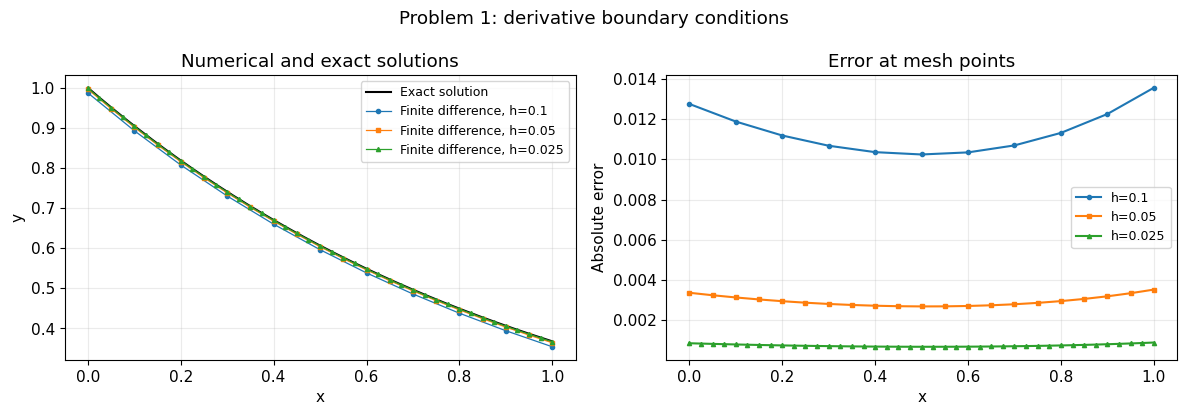

In [ ]:
#Q1

def solve_fd_robin(h):
    x = uniform_mesh(h)
    M = len(x) - 1
    A = np.zeros((M + 1, M + 1))
    b = np.zeros(M + 1)

    # Second-order one-sided boundary derivative equations, scaled by 2h.
    A[0, 0:3] = [2*h - 3, 4.0, -1.0]
    A[M, M-2:M+1] = [-1.0, 4.0, 2*h - 3]
    b[M] = 4*h / np.e

    # Centered interior equations, scaled by h^2.
    for i in range(1, M):
        A[i, i-1] = 1 + h/2
        A[i, i] = -(2 + 2*h*h)
        A[i, i+1] = 1 - h/2

    y = np.linalg.solve(A, b)
    return {"h": h, "x": x, "y": y, "A": A, "b": b}


fd1 = [solve_fd_robin(h) for h in HS]
for r in fd1:
    display(Markdown(f'### Mesh table: h = {r["h"]:g}'))
    mesh_table(r["x"], r["y"], exact_robin)

display(Markdown("### Convergence"))
errors1 = convergence_table(fd1, exact_robin)
plot_fd(fd1, exact_robin, "Problem 1: derivative boundary conditions")

h = 0.1: A Y = b, with Y = (y_1,...,y_9)^T
A =
 [[-2.01  1.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 1.   -2.01  1.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    1.   -2.01  1.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    1.   -2.01  1.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    1.   -2.01  1.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    1.   -2.01  1.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    1.   -2.01  1.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    1.   -2.01  1.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    1.   -2.01]]
b = [0.001 0.002 0.003 0.004 0.005 0.006 0.007 0.008 0.009]


### Mesh table: h = 0.1

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 0.0000000000 | 0.0000000000 | +0.00000e+00 | 0.00000e+00 |
| 1 | 0.100 | -0.0147553114 | -0.0147662966 | +1.09852e-05 | 1.09852e-05 |
| 2 | 0.200 | -0.0286581759 | -0.0286795456 | +2.13697e-05 | 2.13697e-05 |
| 3 | 0.300 | -0.0408476221 | -0.0408781619 | +3.05398e-05 | 3.05398e-05 |
| 4 | 0.400 | -0.0504455446 | -0.0504833998 | +3.78552e-05 | 3.78552e-05 |
| 5 | 0.500 | -0.0565479225 | -0.0565905580 | +4.26355e-05 | 4.26355e-05 |
| 6 | 0.600 | -0.0582157796 | -0.0582599255 | +4.41459e-05 | 4.41459e-05 |
| 7 | 0.700 | -0.0544657946 | -0.0545073763 | +4.15818e-05 | 4.15818e-05 |
| 8 | 0.800 | -0.0442604674 | -0.0442945200 | +3.40525e-05 | 3.40525e-05 |
| 9 | 0.900 | -0.0264977450 | -0.0265183092 | +2.05642e-05 | 2.05642e-05 |
| 10 | 1.000 | 0.0000000000 | 0.0000000000 | +0.00000e+00 | 0.00000e+00 |

### Mesh table: h = 0.05

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 0.0000000000 | 0.0000000000 | +0.00000e+00 | 0.00000e+00 |
| 1 | 0.050 | -0.0074349801 | -0.0074363639 | +1.38378e-06 | 1.38378e-06 |
| 2 | 0.100 | -0.0147635477 | -0.0147662966 | +2.74886e-06 | 2.74886e-06 |
| 3 | 0.150 | -0.0218790242 | -0.0218831006 | +4.07641e-06 | 4.07641e-06 |
| 4 | 0.200 | -0.0286741982 | -0.0286795456 | +5.34741e-06 | 5.34741e-06 |
| 5 | 0.250 | -0.0350410577 | -0.0350476002 | +6.54255e-06 | 6.54255e-06 |
| 6 | 0.300 | -0.0408705198 | -0.0408781619 | +7.64208e-06 | 7.64208e-06 |
| 7 | 0.350 | -0.0460521583 | -0.0460607840 | +8.62575e-06 | 8.62575e-06 |
| 8 | 0.400 | -0.0504739271 | -0.0504833998 | +9.47266e-06 | 9.47266e-06 |
| 9 | 0.450 | -0.0540218808 | -0.0540320420 | +1.01612e-05 | 1.01612e-05 |
| 10 | 0.500 | -0.0565798891 | -0.0565905580 | +1.06689e-05 | 1.06689e-05 |
| 11 | 0.550 | -0.0580293472 | -0.0580403195 | +1.09723e-05 | 1.09723e-05 |
| 12 | 0.600 | -0.0582488787 | -0.0582599255 | +1.10469e-05 | 1.10469e-05 |
| 13 | 0.650 | -0.0571140323 | -0.0571248992 | +1.08669e-05 | 1.08669e-05 |
| 14 | 0.700 | -0.0544969710 | -0.0545073763 | +1.04053e-05 | 1.04053e-05 |
| 15 | 0.750 | -0.0502661522 | -0.0502757856 | +9.63346e-06 | 9.63346e-06 |
| 16 | 0.800 | -0.0442859987 | -0.0442945200 | +8.52124e-06 | 8.52124e-06 |
| 17 | 0.850 | -0.0364165603 | -0.0364235969 | +7.03669e-06 | 7.03669e-06 |
| 18 | 0.900 | -0.0265131632 | -0.0265183092 | +5.14596e-06 | 5.14596e-06 |
| 19 | 0.950 | -0.0144260490 | -0.0144288622 | +2.81312e-06 | 2.81312e-06 |
| 20 | 1.000 | 0.0000000000 | 0.0000000000 | +0.00000e+00 | 0.00000e+00 |

### Mesh table: h = 0.025

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 0.0000000000 | 0.0000000000 | +0.00000e+00 | 0.00000e+00 |
| 1 | 0.025 | -0.0037246575 | -0.0037248308 | +1.73305e-07 | 1.73305e-07 |
| 2 | 0.050 | -0.0074360179 | -0.0074363639 | +3.46027e-07 | 3.46027e-07 |
| 3 | 0.075 | -0.0111207758 | -0.0111212934 | +5.17579e-07 | 5.17579e-07 |
| 4 | 0.100 | -0.0147656092 | -0.0147662966 | +6.87375e-07 | 6.87375e-07 |
| 5 | 0.125 | -0.0183571711 | -0.0183580259 | +8.54826e-07 | 8.54826e-07 |
| 6 | 0.150 | -0.0218820812 | -0.0218831006 | +1.01934e-06 | 1.01934e-06 |
| 7 | 0.175 | -0.0253269176 | -0.0253280980 | +1.18032e-06 | 1.18032e-06 |
| 8 | 0.200 | -0.0286782084 | -0.0286795456 | +1.33717e-06 | 1.33717e-06 |
| 9 | 0.225 | -0.0319224230 | -0.0319239123 | +1.48927e-06 | 1.48927e-06 |
| 10 | 0.250 | -0.0350459642 | -0.0350476002 | +1.63602e-06 | 1.63602e-06 |
| 11 | 0.275 | -0.0380351591 | -0.0380369359 | +1.77680e-06 | 1.77680e-06 |
| 12 | 0.300 | -0.0408762509 | -0.0408781619 | +1.91097e-06 | 1.91097e-06 |
| 13 | 0.325 | -0.0435553904 | -0.0435574283 | +2.03790e-06 | 2.03790e-06 |
| 14 | 0.350 | -0.0460586271 | -0.0460607840 | +2.15694e-06 | 2.15694e-06 |
| 15 | 0.375 | -0.0483719003 | -0.0483741678 | +2.26744e-06 | 2.26744e-06 |
| 16 | 0.400 | -0.0504810310 | -0.0504833998 | +2.36872e-06 | 2.36872e-06 |
| 17 | 0.425 | -0.0523717124 | -0.0523741725 | +2.46011e-06 | 2.46011e-06 |
| 18 | 0.450 | -0.0540295011 | -0.0540320420 | +2.54090e-06 | 2.54090e-06 |
| 19 | 0.475 | -0.0554398082 | -0.0554424186 | +2.61039e-06 | 2.61039e-06 |
| 20 | 0.500 | -0.0565878902 | -0.0565905580 | +2.66785e-06 | 2.66785e-06 |
| 21 | 0.525 | -0.0574588396 | -0.0574615521 | +2.71255e-06 | 2.71255e-06 |
| 22 | 0.550 | -0.0580375758 | -0.0580403195 | +2.74372e-06 | 2.74372e-06 |
| 23 | 0.575 | -0.0583088355 | -0.0583115961 | +2.76060e-06 | 2.76060e-06 |
| 24 | 0.600 | -0.0582571632 | -0.0582599255 | +2.76237e-06 | 2.76237e-06 |
| 25 | 0.625 | -0.0578669016 | -0.0578696498 | +2.74824e-06 | 2.74824e-06 |
| 26 | 0.650 | -0.0571221818 | -0.0571248992 | +2.71737e-06 | 2.71737e-06 |
| 27 | 0.675 | -0.0560069135 | -0.0560095823 | +2.66890e-06 | 2.66890e-06 |
| 28 | 0.700 | -0.0545047744 | -0.0545073763 | +2.60194e-06 | 2.60194e-06 |
| 29 | 0.725 | -0.0525992008 | -0.0526017164 | +2.51560e-06 | 2.51560e-06 |
| 30 | 0.750 | -0.0502733767 | -0.0502757856 | +2.40894e-06 | 2.40894e-06 |
| 31 | 0.775 | -0.0475102235 | -0.0475125045 | +2.28100e-06 | 2.28100e-06 |
| 32 | 0.800 | -0.0442923891 | -0.0442945200 | +2.13082e-06 | 2.13082e-06 |
| 33 | 0.825 | -0.0406022375 | -0.0406041949 | +1.95736e-06 | 1.95736e-06 |
| 34 | 0.850 | -0.0364218374 | -0.0364235969 | +1.75959e-06 | 1.75959e-06 |
| 35 | 0.875 | -0.0317329508 | -0.0317344872 | +1.53644e-06 | 1.53644e-06 |
| 36 | 0.900 | -0.0265170224 | -0.0265183092 | +1.28680e-06 | 1.28680e-06 |
| 37 | 0.925 | -0.0207551670 | -0.0207561766 | +1.00953e-06 | 1.00953e-06 |
| 38 | 0.950 | -0.0144281587 | -0.0144288622 | +7.03450e-07 | 7.03450e-07 |
| 39 | 0.975 | -0.0075164180 | -0.0075167853 | +3.67357e-07 | 3.67357e-07 |
| 40 | 1.000 | 0.0000000000 | 0.0000000000 | +0.00000e+00 | 0.00000e+00 |

### Convergence

| h | M | E_h | E_previous / E_h | observed order p |
| --- | --- | --- | --- | --- |
| 0.100 | 10 | 4.41459147e-05 | - | - |
| 0.050 | 20 | 1.10468911e-05 | 3.996230 | 1.998640 |
| 0.025 | 40 | 2.76237451e-06 | 3.999056 | 1.999660 |

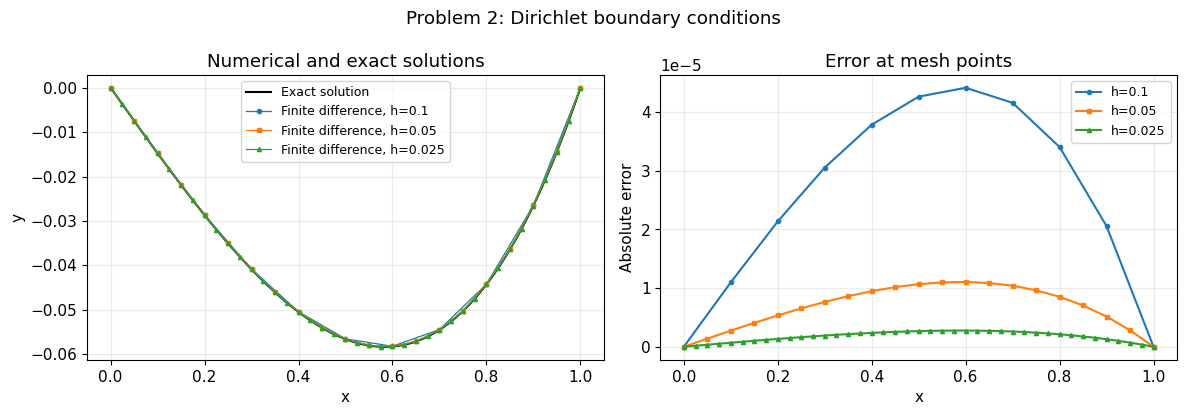

In [ ]:
#Q2

def solve_fd_dirichlet(h):
    x = uniform_mesh(h)
    M = len(x) - 1
    A = np.zeros((M - 1, M - 1))
    b = np.zeros(M - 1)
    for row in range(M - 1):
        i = row + 1
        A[row, row] = -(2 + h*h)
        if row > 0:
            A[row, row-1] = 1.0
        if row < M - 2:
            A[row, row+1] = 1.0
        b[row] = h*h*x[i]

    y = np.zeros(M + 1)  # Both endpoint values are exactly zero.
    y[1:M] = np.linalg.solve(A, b)
    return {"h": h, "x": x, "y": y, "A": A, "b": b}


fd2 = [solve_fd_dirichlet(h) for h in HS]
print("h = 0.1: A Y = b, with Y = (y_1,...,y_9)^T")
print("A =\n", fd2[0]["A"])
print("b =", fd2[0]["b"])
for r in fd2:
    display(Markdown(f'### Mesh table: h = {r["h"]:g}'))
    mesh_table(r["x"], r["y"], exact_dirichlet)

display(Markdown("### Convergence"))
errors2 = convergence_table(fd2, exact_dirichlet)
plot_fd(fd2, exact_dirichlet, "Problem 2: Dirichlet boundary conditions")

### h = 0.1: 5 Newton iterations

| Newton update | max change | max scaled residual |F_i| |
| --- | --- | --- |
| 1 | 1.068702e+00 | 1.142125e-02 |
| 2 | 6.388810e-02 | 4.081690e-05 |
| 3 | 2.301320e-04 | 5.296077e-10 |
| 4 | 2.890892e-09 | 3.885781e-16 |
| 5 | 0.000000e+00 | 3.885781e-16 |

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 6.0000000000 | 6.0000000000 | +0.00000e+00 | 0.00000e+00 |
| 1 | 0.100 | 4.9634837365 | 4.9586776860 | +4.80605e-03 | 4.80605e-03 |
| 2 | 0.200 | 4.1733291809 | 4.1666666667 | +6.66251e-03 | 6.66251e-03 |
| 3 | 0.300 | 3.5573413899 | 3.5502958580 | +7.04553e-03 | 7.04553e-03 |
| 4 | 0.400 | 3.0679003766 | 3.0612244898 | +6.67589e-03 | 6.67589e-03 |
| 5 | 0.500 | 2.6725794904 | 2.6666666667 | +5.91282e-03 | 5.91282e-03 |
| 6 | 0.600 | 2.3486854156 | 2.3437500000 | +4.93542e-03 | 4.93542e-03 |
| 7 | 0.700 | 2.0799545725 | 2.0761245675 | +3.83001e-03 | 3.83001e-03 |
| 8 | 0.800 | 1.8544858398 | 1.8518518519 | +2.63399e-03 | 2.63399e-03 |
| 9 | 0.900 | 1.6634082843 | 1.6620498615 | +1.35842e-03 | 1.35842e-03 |
| 10 | 1.000 | 1.5000000000 | 1.5000000000 | +0.00000e+00 | 0.00000e+00 |

### h = 0.05: 5 Newton iterations

| Newton update | max change | max scaled residual |F_i| |
| --- | --- | --- |
| 1 | 1.073435e+00 | 2.880657e-03 |
| 2 | 6.472264e-02 | 1.047255e-05 |
| 3 | 2.311268e-04 | 1.335491e-10 |
| 4 | 2.905834e-09 | 9.159340e-16 |
| 5 | 0.000000e+00 | 9.159340e-16 |

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 6.0000000000 | 6.0000000000 | +0.00000e+00 | 0.00000e+00 |
| 1 | 0.050 | 5.4429177563 | 5.4421768707 | +7.40886e-04 | 7.40886e-04 |
| 2 | 0.100 | 4.9598988968 | 4.9586776860 | +1.22121e-03 | 1.22121e-03 |
| 3 | 0.150 | 4.5383815300 | 4.5368620038 | +1.51953e-03 | 1.51953e-03 |
| 4 | 0.200 | 4.1683564305 | 4.1666666667 | +1.68976e-03 | 1.68976e-03 |
| 5 | 0.250 | 3.8417693193 | 3.8400000000 | +1.76932e-03 | 1.76932e-03 |
| 6 | 0.300 | 3.5520801869 | 3.5502958580 | +1.78433e-03 | 1.78433e-03 |
| 7 | 0.350 | 3.2939342386 | 3.2921810700 | +1.75317e-03 | 1.75317e-03 |
| 8 | 0.400 | 3.0629132972 | 3.0612244898 | +1.68881e-03 | 1.68881e-03 |
| 9 | 0.450 | 2.8553459505 | 2.8537455410 | +1.60041e-03 | 1.60041e-03 |
| 10 | 0.500 | 2.6681611050 | 2.6666666667 | +1.49444e-03 | 1.49444e-03 |
| 11 | 0.550 | 2.4987739688 | 2.4973985432 | +1.37543e-03 | 1.37543e-03 |
| 12 | 0.600 | 2.3449965109 | 2.3437500000 | +1.24651e-03 | 1.24651e-03 |
| 13 | 0.650 | 2.2049665746 | 2.2038567493 | +1.10983e-03 | 1.10983e-03 |
| 14 | 0.700 | 2.0770913322 | 2.0761245675 | +9.66765e-04 | 9.66765e-04 |
| 15 | 0.750 | 1.9600018609 | 1.9591836735 | +8.18187e-04 | 8.18187e-04 |
| 16 | 0.800 | 1.8525164079 | 1.8518518519 | +6.64556e-04 | 6.64556e-04 |
| 17 | 0.850 | 1.7536104974 | 1.7531044558 | +5.06042e-04 | 5.06042e-04 |
| 18 | 0.900 | 1.6623924614 | 1.6620498615 | +3.42600e-04 | 3.42600e-04 |
| 19 | 0.950 | 1.5780832971 | 1.5779092702 | +1.74027e-04 | 1.74027e-04 |
| 20 | 1.000 | 1.5000000000 | 1.5000000000 | +0.00000e+00 | 0.00000e+00 |

### h = 0.025: 5 Newton iterations

| Newton update | max change | max scaled residual |F_i| |
| --- | --- | --- |
| 1 | 1.076157e+00 | 7.238210e-04 |
| 2 | 6.479496e-02 | 2.623992e-06 |
| 3 | 2.314133e-04 | 3.346996e-11 |
| 4 | 2.910617e-09 | 7.537374e-16 |
| 5 | 4.440892e-16 | 7.537374e-16 |

| i | x_i | y_i | exact y(x_i) | signed error | absolute error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.000 | 6.0000000000 | 6.0000000000 | +0.00000e+00 | 0.00000e+00 |
| 1 | 0.025 | 5.7109891495 | 5.7108863772 | +1.02772e-04 | 1.02772e-04 |
| 2 | 0.050 | 5.4423629221 | 5.4421768707 | +1.86051e-04 | 1.86051e-04 |
| 3 | 0.075 | 5.1922487662 | 5.1919956733 | +2.53093e-04 | 2.53093e-04 |
| 4 | 0.100 | 4.9589842647 | 4.9586776860 | +3.06579e-04 | 3.06579e-04 |
| 5 | 0.125 | 4.7410894663 | 4.7407407407 | +3.48726e-04 | 3.48726e-04 |
| 6 | 0.150 | 4.5372433738 | 4.5368620038 | +3.81370e-04 | 3.81370e-04 |
| 7 | 0.175 | 4.3462638921 | 4.3458578542 | +4.06038e-04 | 4.06038e-04 |
| 8 | 0.200 | 4.1670906666 | 4.1666666667 | +4.24000e-04 | 4.24000e-04 |
| 9 | 0.225 | 3.9987703440 | 3.9983340275 | +4.36317e-04 | 4.36317e-04 |
| 10 | 0.250 | 3.8404438741 | 3.8400000000 | +4.43874e-04 | 4.43874e-04 |
| 11 | 0.275 | 3.6913355348 | 3.6908881200 | +4.47415e-04 | 4.47415e-04 |
| 12 | 0.300 | 3.5507434194 | 3.5502958580 | +4.47561e-04 | 4.47561e-04 |
| 13 | 0.325 | 3.4180311657 | 3.4175863297 | +4.44836e-04 | 4.44836e-04 |
| 14 | 0.350 | 3.2926207476 | 3.2921810700 | +4.39678e-04 | 4.39678e-04 |
| 15 | 0.375 | 3.1739861742 | 3.1735537190 | +4.32455e-04 | 4.32455e-04 |
| 16 | 0.400 | 3.0616479684 | 3.0612244898 | +4.23479e-04 | 4.23479e-04 |
| 17 | 0.425 | 2.9551683178 | 2.9547553093 | +4.13009e-04 | 4.13009e-04 |
| 18 | 0.450 | 2.8541468046 | 2.8537455410 | +4.01264e-04 | 4.01264e-04 |
| 19 | 0.475 | 2.7582166376 | 2.7578282103 | +3.88427e-04 | 3.88427e-04 |
| 20 | 0.500 | 2.6670413200 | 2.6666666667 | +3.74653e-04 | 3.74653e-04 |
| 21 | 0.525 | 2.5803116958 | 2.5799516259 | +3.60070e-04 | 3.60070e-04 |
| 22 | 0.550 | 2.4977433268 | 2.4973985432 | +3.44784e-04 | 3.44784e-04 |
| 23 | 0.575 | 2.4190741590 | 2.4187452759 | +3.28883e-04 | 3.28883e-04 |
| 24 | 0.600 | 2.3440624410 | 2.3437500000 | +3.12441e-04 | 3.12441e-04 |
| 25 | 0.625 | 2.2724848659 | 2.2721893491 | +2.95517e-04 | 2.95517e-04 |
| 26 | 0.650 | 2.2041349080 | 2.2038567493 | +2.78159e-04 | 2.78159e-04 |
| 27 | 0.675 | 2.1388213318 | 2.1385609267 | +2.60405e-04 | 2.60405e-04 |
| 28 | 0.700 | 2.0763668536 | 2.0761245675 | +2.42286e-04 | 2.42286e-04 |
| 29 | 0.725 | 2.0166069374 | 2.0163831128 | +2.23825e-04 | 2.23825e-04 |
| 30 | 0.750 | 1.9593887109 | 1.9591836735 | +2.05037e-04 | 2.05037e-04 |
| 31 | 0.775 | 1.9045699870 | 1.9043840508 | +1.85936e-04 | 1.85936e-04 |
| 32 | 0.800 | 1.8520183798 | 1.8518518519 | +1.66528e-04 | 1.66528e-04 |
| 33 | 0.825 | 1.8016105052 | 1.8014636892 | +1.46816e-04 | 1.46816e-04 |
| 34 | 0.850 | 1.7532312559 | 1.7531044558 | +1.26800e-04 | 1.26800e-04 |
| 35 | 0.875 | 1.7067731440 | 1.7066666667 | +1.06477e-04 | 1.06477e-04 |
| 36 | 0.900 | 1.6621357036 | 1.6620498615 | +8.58421e-05 | 8.58421e-05 |
| 37 | 0.925 | 1.6192249477 | 1.6191600607 | +6.48870e-05 | 6.48870e-05 |
| 38 | 0.950 | 1.5779528727 | 1.5779092702 | +4.36025e-05 | 4.36025e-05 |
| 39 | 0.975 | 1.5382370073 | 1.5382150296 | +2.19776e-05 | 2.19776e-05 |
| 40 | 1.000 | 1.5000000000 | 1.5000000000 | +0.00000e+00 | 0.00000e+00 |

### Discretization error and convergence

| h | M | E_h | E_previous / E_h | observed order p |
| --- | --- | --- | --- | --- |
| 0.100 | 10 | 7.04553193e-03 | - | - |
| 0.050 | 20 | 1.78432889e-03 | 3.948561 | 1.981327 |
| 0.025 | 40 | 4.47561384e-04 | 3.986780 | 1.995224 |

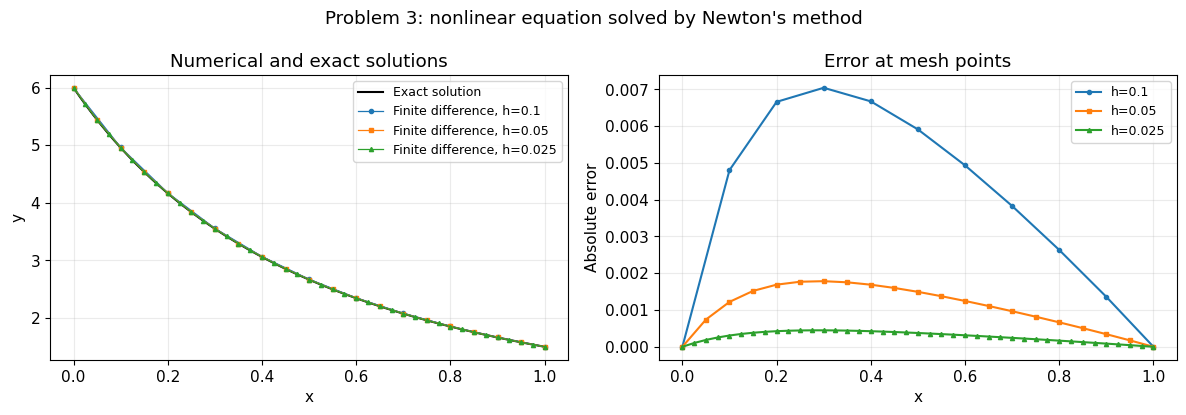

In [3]:
def nonlinear_residual_jacobian(u, h):
    n = len(u)
    y = np.empty(n + 2)
    y[0], y[-1] = 6.0, 1.5
    y[1:-1] = u
    F = np.zeros(n)
    J = np.zeros((n, n))
    for row in range(n):
        i = row + 1
        F[row] = y[i-1] - 2*y[i] + y[i+1] - h*h*y[i]**2
        J[row, row] = -2 - 2*h*h*y[i]
        if row > 0:
            J[row, row-1] = 1.0
        if row < n - 1:
            J[row, row+1] = 1.0
    return F, J


def solve_fd_nonlinear(h, tol=NEWTON_TOL, max_iter=100):
    x = uniform_mesh(h)
    u = 6.0 - 4.5*x[1:-1]  # Required straight-line initial guess.
    history = []
    for iteration in range(1, max_iter + 1):
        F, J = nonlinear_residual_jacobian(u, h)
        delta = np.linalg.solve(J, -F)
        u_new = u + delta
        step = float(np.max(np.abs(u_new - u)))
        F_new, _ = nonlinear_residual_jacobian(u_new, h)
        residual = float(np.max(np.abs(F_new)))
        history.append((iteration, step, residual))
        u = u_new
        if step < tol:
            y = np.empty(len(x))
            y[0], y[-1] = 6.0, 1.5
            y[1:-1] = u
            return {"h": h, "x": x, "y": y,
                    "iterations": iteration, "history": history}
    raise RuntimeError(f"Newton did not converge in {max_iter} iterations.")


fd3 = [solve_fd_nonlinear(h) for h in HS]
for r in fd3:
    display(Markdown(f'### h = {r["h"]:g}: {r["iterations"]} Newton iterations'))
    table(["Newton update", "max change", "max scaled residual |F_i|"],
          [[k, f"{step:.6e}", f"{residual:.6e}"]
           for k, step, residual in r["history"]])
    mesh_table(r["x"], r["y"], exact_nonlinear)

display(Markdown("### Discretization error and convergence"))
errors3 = convergence_table(fd3, exact_nonlinear)
plot_fd(fd3, exact_nonlinear, "Problem 3: nonlinear equation solved by Newton's method")

### Coefficients in ascending powers: c_0, ..., c_N

| N | c_0 | c_1 | c_2 | c_3 | c_4 | c_5 | c_6 | c_7 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3 | 9.6409784583e-01 | -9.6409784583e-01 | 4.4324622324e-01 | -1.0745362988e-01 | - | - | - | - |
| 4 | 9.9739624147e-01 | -9.9739624147e-01 | 4.9249385248e-01 | -1.5236528561e-01 | 2.4624692624e-02 | - | - | - |
| 5 | 9.9966733127e-01 | -9.9966733127e-01 | 4.9924713500e-01 | -1.6470515831e-01 | 3.8128989074e-02 | -5.0788341706e-03 | - | - |
| 6 | 9.9998820673e-01 | -9.9998820673e-01 | 4.9994810492e-01 | -1.6646563284e-01 | 4.1161053970e-02 | -7.6226603475e-03 | 8.4399292603e-04 | - |
| 7 | 9.9999883815e-01 | -9.9999883815e-01 | 4.9999644824e-01 | -1.6665023390e-01 | 4.1613348410e-02 | -8.2301701099e-03 | 1.2697108730e-03 | -1.2065729864e-04 |

| N | max absolute error on 10,001 points |
| --- | --- |
| 3 | 3.5902154171e-02 |
| 4 | 3.1261816808e-03 |
| 5 | 3.3266872846e-04 |
| 6 | 1.4582545673e-05 |
| 7 | 1.1618474389e-06 |

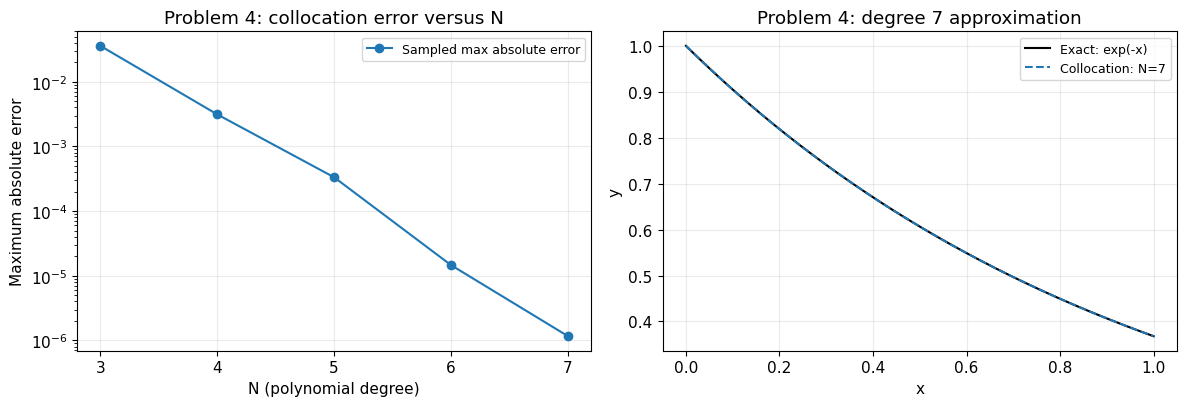

In [4]:
def monomial(j, x, derivative=0):
    x = np.asarray(x, dtype=float)
    if derivative == 0:
        return x**j
    if derivative == 1:
        return np.zeros_like(x) if j == 0 else j*x**(j-1)
    if derivative == 2:
        return np.zeros_like(x) if j < 2 else j*(j-1)*x**(j-2)
    raise ValueError("Only derivative orders 0, 1, 2 are used.")


def evaluate_polynomial(c, x, derivative=0):
    values = np.zeros_like(np.asarray(x, dtype=float))
    for j, cj in enumerate(c):
        values += cj*monomial(j, x, derivative)
    return values


def solve_collocation_robin(N):
    points = np.array([k/N for k in range(1, N)])
    A = np.zeros((N + 1, N + 1))
    b = np.zeros(N + 1)
    A[0, 0], A[0, 1] = 1.0, 1.0
    for row, xk in enumerate(points, start=1):
        for j in range(N + 1):
            A[row, j] = (monomial(j, xk, 2) - monomial(j, xk, 1)
                         - 2*monomial(j, xk))
    for j in range(N + 1):
        A[N, j] = 1 - j
    b[N] = 2 / np.e
    c = np.linalg.solve(A, b)
    error = float(np.max(np.abs(evaluate_polynomial(c, X_FINE) - exact_robin(X_FINE))))
    return {"N": N, "c": c, "points": points, "A": A, "b": b, "error": error}


coll4 = [solve_collocation_robin(N) for N in range(3, 8)]
display(Markdown("### Coefficients in ascending powers: c_0, ..., c_N"))
table(["N"] + [f"c_{j}" for j in range(8)],
      [[r["N"]] + [f'{r["c"][j]:.10e}' if j <= r["N"] else "-"
                     for j in range(8)] for r in coll4])
table(["N", "max absolute error on 10,001 points"],
      [[r["N"], f'{r["error"]:.10e}'] for r in coll4])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogy([r["N"] for r in coll4], [r["error"] for r in coll4], "o-",
                 label="Sampled max absolute error")
axes[0].set(xlabel="N (polynomial degree)", ylabel="Maximum absolute error",
            title="Problem 4: collocation error versus N", xticks=range(3, 8))
axes[1].plot(X_FINE, exact_robin(X_FINE), "k-", label="Exact: exp(-x)")
axes[1].plot(X_FINE, evaluate_polynomial(coll4[-1]["c"], X_FINE), "--",
             label="Collocation: N=7")
axes[1].set(xlabel="x", ylabel="y", title="Problem 4: degree 7 approximation")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### Coefficients for x^i(1-x): c_1, ..., c_N

| N | c_1 | c_2 | c_3 | c_4 | c_5 | c_6 |
| --- | --- | --- | --- | --- | --- | --- |
| 2 | -1.4464285714e-01 | -1.6071428571e-01 | - | - | - | - |
| 3 | -1.5018437421e-01 | -1.4304390393e-01 | -1.8572257690e-02 | - | - | - |
| 4 | -1.4904401388e-01 | -1.4932456371e-01 | -6.5758657379e-03 | -8.0361046108e-03 | - | - |
| 5 | -1.4908767333e-01 | -1.4902793308e-01 | -7.4804344797e-03 | -6.8142787998e-03 | -6.1870553054e-04 | - |
| 6 | -1.4908173154e-01 | -1.4908333473e-01 | -7.2546534341e-03 | -7.2826461368e-03 | -1.4154303882e-04 | -1.9119178881e-04 |

| N | max absolute error on 10,001 points |
| --- | --- |
| 2 | 5.8105151902e-04 |
| 3 | 6.3081021296e-05 |
| 4 | 2.4792041279e-06 |
| 5 | 2.1458505762e-07 |
| 6 | 5.8747427999e-09 |

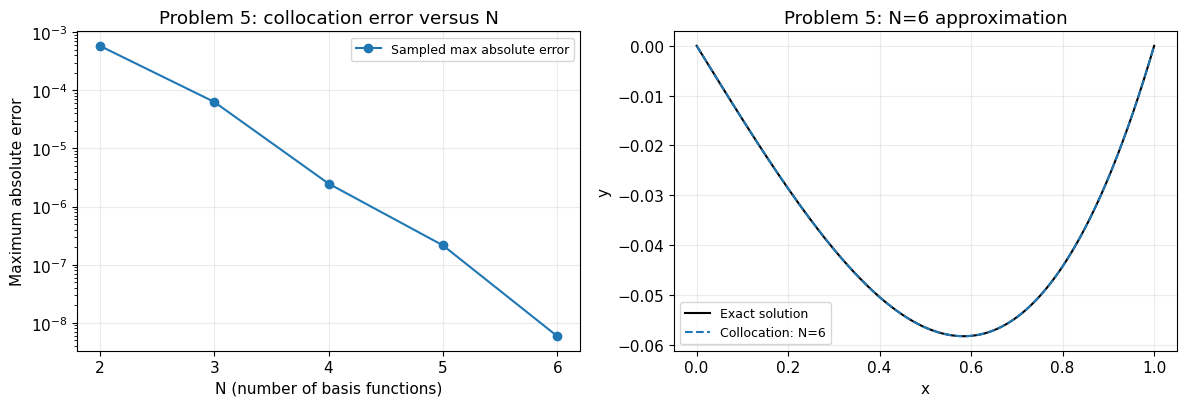

In [6]:
def dirichlet_basis(i, x, derivative=0):
    return monomial(i, x, derivative) - monomial(i+1, x, derivative)


def evaluate_dirichlet_trial(c, x, derivative=0):
    values = np.zeros_like(np.asarray(x, dtype=float))
    for i, ci in enumerate(c, start=1):
        values += ci*dirichlet_basis(i, x, derivative)
    return values


def solve_collocation_dirichlet(N):
    points = np.array([k/(N+1) for k in range(1, N+1)])
    A = np.zeros((N, N))
    b = np.zeros(N)
    for row, xk in enumerate(points):
        b[row] = xk
        for col in range(N):
            i = col + 1
            A[row, col] = dirichlet_basis(i, xk, 2) - dirichlet_basis(i, xk)
    c = np.linalg.solve(A, b)
    error = float(np.max(np.abs(evaluate_dirichlet_trial(c, X_FINE)
                                - exact_dirichlet(X_FINE))))
    return {"N": N, "c": c, "points": points, "A": A, "b": b, "error": error}


coll5 = [solve_collocation_dirichlet(N) for N in range(2, 7)]
display(Markdown("### Coefficients for x^i(1-x): c_1, ..., c_N"))
table(["N"] + [f"c_{i}" for i in range(1, 7)],
      [[r["N"]] + [f'{r["c"][i-1]:.10e}' if i <= r["N"] else "-"
                     for i in range(1, 7)] for r in coll5])
table(["N", "max absolute error on 10,001 points"],
      [[r["N"], f'{r["error"]:.10e}'] for r in coll5])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogy([r["N"] for r in coll5], [r["error"] for r in coll5], "o-",
                 label="Sampled max absolute error")
axes[0].set(xlabel="N (number of basis functions)", ylabel="Maximum absolute error",
            title="Problem 5: collocation error versus N", xticks=range(2, 7))
axes[1].plot(X_FINE, exact_dirichlet(X_FINE), "k-", label="Exact solution")
axes[1].plot(X_FINE, evaluate_dirichlet_trial(coll5[-1]["c"], X_FINE), "--",
             label="Collocation: N=6")
axes[1].set(xlabel="x", ylabel="y", title="Problem 5: N=6 approximation")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

In [7]:
c6 = coll5[-1]["c"]
comparison_rows = []
for r, fd_error in zip(fd2, errors2):
    coll_at_fd_nodes = float(np.max(np.abs(evaluate_dirichlet_trial(c6, r["x"])
                                          - exact_dirichlet(r["x"]))))
    comparison_rows.append([f'{r["h"]:g}', len(r["x"])-2,
                            f"{fd_error:.8e}", f"{coll_at_fd_nodes:.8e}",
                            f'{coll5[-1]["error"]:.8e}',
                            f"{fd_error/coll_at_fd_nodes:.2f}"])
table(["FD h", "FD interior unknowns", "FD max error at nodes",
       "N=6 collocation error at same nodes", "N=6 collocation fine-mesh error",
       "FD error / collocation error at same nodes"], comparison_rows)
print("The N=6 collocation system has 6 unknown coefficients.")

| FD h | FD interior unknowns | FD max error at nodes | N=6 collocation error at same nodes | N=6 collocation fine-mesh error | FD error / collocation error at same nodes |
| --- | --- | --- | --- | --- | --- |
| 0.1 | 9 | 4.41459147e-05 | 5.86360691e-09 | 5.87474280e-09 | 7528.80 |
| 0.05 | 19 | 1.10468911e-05 | 5.86360691e-09 | 5.87474280e-09 | 1883.98 |
| 0.025 | 39 | 2.76237451e-06 | 5.86360691e-09 | 5.87474280e-09 | 471.10 |

The N=6 collocation system has 6 unknown coefficients.
